# Riconoscere un gatto con le regole

Proviamo a riconoscere un gatto **scrivendo noi le regole**: contorni, forme rotonde, colori.
Poi la stessa idea con l'hot dog.

Carica una foto quando la cella lo chiede, e guarda quante volte le regole sbagliano.

In [ ]:
#! (Exclamation Mark): In a Colab notebook, the exclamation mark preceding a command tells the notebook to execute the command in the underlying operating system
# instead of within the Python interpreter.

!pip install opencv-python
!pip install matplotlib

In [ ]:
import os
import cv2  #classical computer vision techniques
import numpy as np
from google.colab import files
from io import BytesIO
from PIL import Image
from urllib.request import urlopen, Request
from matplotlib import pyplot as plt

# OpenCV (cv2) uses BGR as its default color format,
# whereas many image libraries, such as Pillow (PIL), use RGB.
def load_image(image_path):
    image = Image.open(BytesIO(uploaded[image_path])) # using Pillow's Image
    image = cv2.cvtColor(np.array(image), cv2.COLOR_RGB2BGR) # NumPy array
    return image

def load_image_from_uri(image_uri):
    # alcuni siti rifiutano le richieste senza User-Agent
    richiesta = Request(image_uri, headers={'User-Agent': 'Mozilla/5.0 (FormazioneAI notebook)'})
    with urlopen(richiesta) as response:
        image_data = response.read()
    image = Image.open(BytesIO(image_data))
    #image = cv2.cvtColor(np.array(image), cv2.COLOR_RGB2BGR)
    image = cv2.cvtColor(np.array(image), cv2.COLOR_RGB2GRAY)
    return image

def display_image(image, title):
    plt.subplot(1, 1, 1)
    if image.ndim == 3:
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)  # OpenCV lavora in BGR, matplotlib in RGB
        plt.imshow(image)
    else:
        plt.imshow(image, cmap='gray')
    plt.title(title)
    plt.show()

In [ ]:
def detect_cat_like_features(image):
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    # Edge detection is a fundamental image processing technique to identify the boundaries of objects in an image. The Canny algorithm is popular due to its effectiveness and robustness.
    # It involves multiple steps to minimize noise and accurately identify edges.
    # Use edge detection to capture potential "whiskers" and "ears"
    edges = cv2.Canny(gray, threshold1=50, threshold2=150)

    # Detect contours, aiming to find face-like ovals and whisker patterns
    # RETR_TREE == family tree. If a contour is inside another, it will be treated as a child of the outer contour
    contours, _ = cv2.findContours(edges, cv2.RETR_TREE, cv2.CHAIN_APPROX_SIMPLE)

    cat_like = False

    # color highlights
    color_index = 0
    colors = [(0, 90, 194), (95, 58, 31)]  # colori del corso (BGR), adatti anche a chi è daltonico

    for contour in contours:
        # Approximate the contour shape
        approx = cv2.approxPolyDP(contour, 0.02 * cv2.arcLength(contour, True), True)
        area = cv2.contourArea(contour)
        # Check for circular/oval shapes
        if len(approx) > 5 and 500 < area < 3000:
            cat_like = True
            # Highlight the contour
            cv2.drawContours(image, [approx], -1, colors[color_index % len(colors)], 4)
            color_index += 1

    if cat_like:
        result = f"OK - {detect_cat_like_features.__name__}";
    else:
        result = f"Failed - {detect_cat_like_features.__name__}";
    display_image(image, result);


In [ ]:
def detect_round_face_cat(image):
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    # Detect circular/oval shapes for the face
    circles = cv2.HoughCircles(gray, cv2.HOUGH_GRADIENT, 1, 20,
                               param1=50, param2=30,
                               minRadius=30, maxRadius=100)
    cat_like = False;
    if circles is not None:
        circles = np.uint16(np.around(circles))
        for i in circles[0, :]:
            # Draw the outer circle
            cv2.circle(image, (int(i[0]), int(i[1])), int(i[2]), (0, 90, 194), 2)
            # Draw the center of the circle
            cv2.circle(image, (int(i[0]), int(i[1])), 2, (95, 58, 31), 3)

            # Region of Interest (ROI) for the detected circle
            x, y, r = (int(v) for v in i)   # int: con uint16, y - r sotto zero darebbe un numero enorme
            roi = image[max(y - r, 0):y + r, max(x - r, 0):x + r]
            if roi.size == 0:
                continue

            # cat-like features:
            # 1. Aspect Ratio: the ROI is roughly circular, not too elongated
            aspect_ratio = roi.shape[1] / roi.shape[0]  # width / height
            if not 0.8 < aspect_ratio < 1.2:  # Adjust the range as needed
                continue  # Skip if not circular enough

            # 2. Color: Cats often have fur within a certain color range
            lower_color = np.array([0, 50, 50])  # Example lower bound (BGR)
            upper_color = np.array([100, 255, 255])  # Example upper bound (BGR)
            mask = cv2.inRange(roi, lower_color, upper_color)
            color_ratio = cv2.countNonZero(mask) / (roi.shape[0] * roi.shape[1])
            if color_ratio < 0.2:  # Adjust the threshold as needed
                continue  # Skip if color doesn't match
            cat_like = True
            break # Exit the loop after finding a potential cat face

    if cat_like:
        result = f"OK - {detect_round_face_cat.__name__}";
    else:
        result = f"Failed - {detect_round_face_cat.__name__}";

    display_image(image, result);

In [ ]:
# I classificatori Haar Cascade sono un modo efficace per il rilevamento di oggetti.
# Questo metodo è stato proposto da Paul Viola e Michael Jones nel loro articolo:
# Rapid Object Detection using a Boosted Cascade of Simple Features.

# Attenzione: questo file riconosce volti UMANI. OpenCV ne ha uno anche per i musi di gatto:
# prova a sostituirlo con 'haarcascade_frontalcatface.xml' e confronta i risultati.
face_cascade = cv2.CascadeClassifier(cv2.data.haarcascades + 'haarcascade_frontalface_default.xml')

def detect_cat_like_features_cascade(image):
    # Convert to grayscale for face detection
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    # Detect faces using Haar Cascade
    faces = face_cascade.detectMultiScale(gray, scaleFactor=1.05, minNeighbors=2)

    if len(faces) > 0:  # Check if faces were detected
        result = f"OK - {detect_cat_like_features_cascade.__name__}";
        for (x, y, w, h) in faces:
            cv2.rectangle(image, (x, y), (x + w, y + h), (0, 90, 194), 4)  # Highlight
    else:
        result = f"Failed - {detect_cat_like_features_cascade.__name__}";


    display_image(image, result);

Saving cat_no_ML.png to cat_no_ML.png


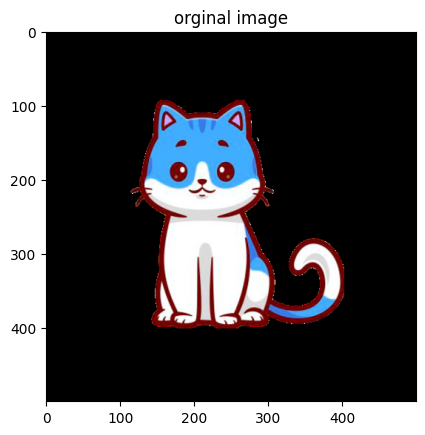

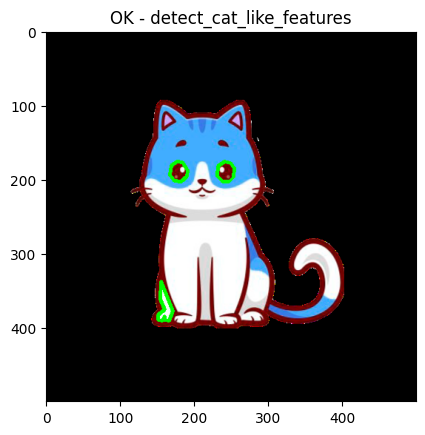

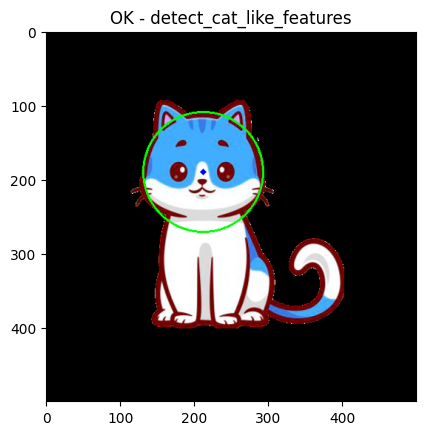

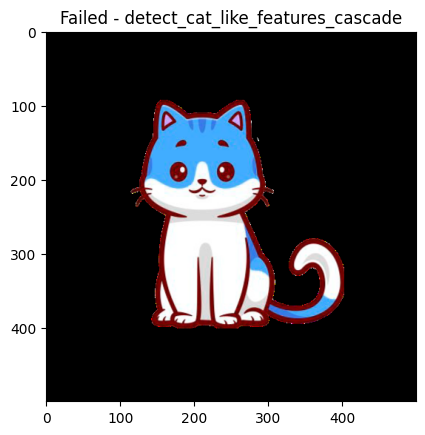

In [ ]:
uploaded = files.upload()
image_path = next(iter(uploaded))

image = load_image(image_path)
display_image(image, "orginal image")



detect_cat_like_features(image.copy())
detect_round_face_cat(image.copy())
detect_cat_like_features_cascade(image.copy())

<img src="https://i.ytimg.com/vi/vIci3C4JkL0/hq720.jpg" width="600" > <br>Jian-Yang - Serie Televisiva Silicon Valley (2014–2019)

In [ ]:
def detect_hot_dog(image, template_image):
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    # Resize template image to be smaller than input image if necessary
    template_height, template_width = template_image.shape[:2]
    image_height, image_width = gray.shape[:2]

    if template_height > image_height or template_width > image_width:
        # Calculate the scaling factor
        scale_factor = min(image_width / template_width, image_height / template_height)

        # Resize the template image
        template_image = cv2.resize(template_image, None, fx=scale_factor, fy=scale_factor)


    # Perform template matching
    res = cv2.matchTemplate(gray, template_image, cv2.TM_CCOEFF_NORMED)
    min_val, max_val, min_loc, max_loc = cv2.minMaxLoc(res)

    # Set a threshold for detection
    threshold = 0.8

    if max_val > threshold:
       # Draw a filled circle in the middle
        center_coordinates = (image.shape[1] // 2, image.shape[0] // 2)
        radius = int(min(image.shape[0], image.shape[1]) * 0.1)  # 10% of the smaller dimension
        color = (95, 58, 31)  # blu notte (BGR)
        thickness = -1  # Fill the circle completely
        cv2.circle(image, center_coordinates, radius, color, thickness)
        result = "Hotdog"
    else:
        cv2.line(image, (0, 0), (image.shape[1], image.shape[0]), (0, 90, 194), 15)  # Top-left to bottom-right
        cv2.line(image, (0, image.shape[0]), (image.shape[1], 0), (0, 90, 194), 15)  # Bottom-left to top-right
        result = "Not Hotdog"

    display_image(image, result)

In [ ]:
def detect_hot_dog_failed(image):
    # Convert to HSV color space for better color-based segmentation
    hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)

    # Define color range for hot dogs (brownish-red)
    # Adjust these ranges as needed for your specific images
    lower_hot_dog = np.array([0, 100, 100])
    upper_hot_dog = np.array([20, 255, 255])

    # Create a mask for hot dog-colored regions
    mask = cv2.inRange(hsv, lower_hot_dog, upper_hot_dog)

    # Apply morphological operations to reduce noise and fill gaps
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel)

    # Find contours in the mask
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    hot_dog_detected = False

    for contour in contours:
        # Approximate the contour shape
        approx = cv2.approxPolyDP(contour, 0.03 * cv2.arcLength(contour, True), True)

        # Check for elongated shape (typical of a hot dog)
        x, y, w, h = cv2.boundingRect(approx)
        aspect_ratio = float(w) / h
        if 2.0 < aspect_ratio < 5.0 and cv2.contourArea(contour) > 1000:
            hot_dog_detected = True
            cv2.drawContours(image, [approx], -1, (0, 90, 194), 2)
            break

    if hot_dog_detected:
        result = f"Hotdog";
    else:
        result = f"Not Hotdog";

    display_image(image, result);

Saving hotdog.png to hotdog.png


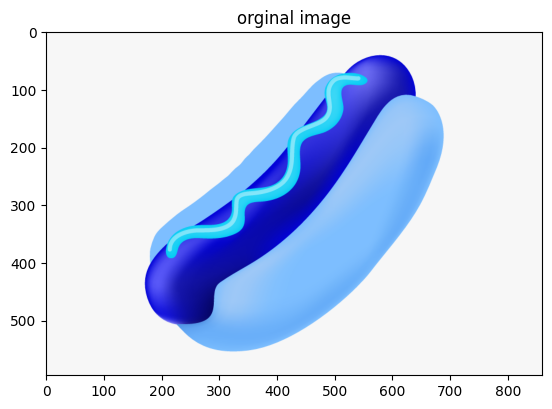

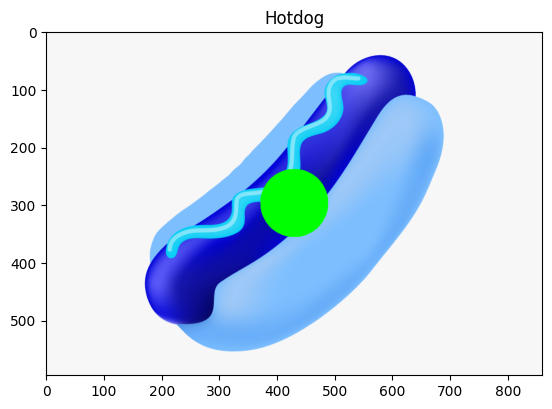

In [ ]:
uploaded = files.upload()
image_path = next(iter(uploaded))

image = load_image(image_path)
display_image(image, "orginal image")

template_uri = "https://www.kindpng.com/picc/m/9-96302_cartoon-hot-dog-clipart-transparent-background-hot-dog.png"
template_image = load_image_from_uri(template_uri)
detect_hot_dog(image.copy(), template_image)